# 05 · Adjusted associations and asking-price prediction

## tl;dr
On the later posting block (98,248 listings in the audited price band), **Gradient boosting** achieved **$4,569 MAE**, **58.4% lower** than the training-median benchmark. In log-OLS (80,000 earlier listings), five additional years of age corresponded to a **10.6% lower** fitted geometric asking price and 10,000 additional miles to a **4.3% lower** fitted geometric asking price at fixed included covariates.

## Context & Methods

The [project proposal](../docs/proposal.md) uses exploratory regression to examine which vehicle characteristics are associated with sellers' asking prices. This notebook adds two complementary analyses. A multivariable log-price regression describes adjusted age and mileage differences. A prediction experiment compares a simple benchmark, regularized linear regression, and gradient-boosted trees on a later posting block.

### Key assumptions

- The target is an advertised asking price in USD. The evaluation conditions on the actual asking price being within the review band, so it applies to that retrospective price range.
- The later holdout is defined by whole local posting days, including the day containing the 80th percentile and every later day. The whole-day boundary can put more than 20% of dated, in-band listings in the holdout. Both learners use the same predictors. Preprocessing is fit on training rows; model settings are fixed before evaluating the holdout.
- To reduce repeated-vehicle leakage, earlier listings with a matching valid-looking VIN **or** exact stable fingerprint in the holdout are removed. The fingerprint combines state, manufacturer, model, model year, odometer, vehicle type and paint color, and requires state, model, model year and odometer. This rule can match different vehicles with identical attributes and can miss reposts with changed fields. Split keys are excluded from models and displayed outputs.
- Log-OLS is additive in age, mileage and the listed category controls. Its transformed contrasts compare fitted geometric asking prices while other included covariates are held fixed. State-clustered intervals describe sampling uncertainty under the working model.

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import statsmodels
from IPython.display import Markdown, display
from matplotlib.ticker import StrMethodFormatter

root = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src" / "price_models.py").is_file()), None)
if root is None:
    raise RuntimeError("Start Jupyter from the repository or its notebooks directory.")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from src.listings import RAW, LOW_PRICE_REVIEW, HIGH_PRICE_REVIEW
from src.price_models import FEATURES, chronological_cohort, prediction_scores, adjusted_associations

plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.axisbelow": True,
                     "grid.alpha": 0.22, "font.size": 10})
blue, pale_blue, grey = "#235D85", "#73A5C5", "#667585"

print(f"pandas {pd.__version__} · scikit-learn {sklearn.__version__} · statsmodels {statsmodels.__version__}")

pandas 2.1.4 · scikit-learn 1.2.2 · statsmodels 0.14.0


## Data

Start with the pinned [Kaggle v10 file](../DATA.md). Read only the columns needed for cleaning, modeling and split protection. Reuse the project's [cleaning rules](02_clean_and_derive.ipynb), then keep observations with valid dates and prices of **$500–$150,000 inclusive**. Treat readings above **1,000,000 miles** as missing. For the predictive models, numerical missingness is imputed with training medians and flagged in ridge, and handled by native missing-value splits in boosting. Both models have an explicit level for missing categories.

Both models use age, mileage, manufacturer, condition, fuel type, vehicle type, title status, transmission, drivetrain and state. Vehicle age already uses model year, so model year is omitted from the predictors.

In [2]:
train, test, counts = chronological_cohort(root / RAW)

stages = [
    ("Positive-price listings after cleaning", counts["source_positive"]),
    (f"Price between ${LOW_PRICE_REVIEW:,} and ${HIGH_PRICE_REVIEW:,}", counts["within_price_band"]),
    ("In-band listings with valid dates", counts["dated_rows"]),
    ("Earlier block before overlap purge", counts["initial_train_n"]),
    ("Earlier listings removed for overlap", counts["purge_n"]),
    ("Final training rows", counts["train_n"]),
    ("Held-out rows", counts["test_n"]),
]
display(pd.DataFrame(stages, columns=["Stage", "Listing count"]).set_index("Stage"))
print(f"Training period: {counts['train_first_day']} to {counts['train_last_day']}")
print(f"Held-out period: {counts['test_first_day']} to {counts['test_last_day']}")
assert counts["train_n"] + counts["purge_n"] + counts["test_n"] == counts["dated_rows"]


,Listing count
Stage,
Positive-price listings after cleaning,393985
"Price between $500 and $150,000",384590
In-band listings with valid dates,384528
Earlier block before overlap purge,286280
Earlier listings removed for overlap,41629
Final training rows,244651
Held-out rows,98248


Training period: 2021-04-04 to 2021-04-30
Held-out period: 2021-05-01 to 2021-05-04


## Results

### Prediction on the later holdout

The benchmark predicts the training median for every listing. Ridge uses one-hot encoding, standardized numerical inputs and L2 regularization. The histogram gradient-boosted tree model uses categorical splits and captures nonlinearities and interactions. Both learned models fit natural log price and exponentiate predictions before calculating errors in dollars. Lower MAE and RMSE are better. Higher R² is better, and the test mean defines its zero benchmark.

,MAE (USD),RMSE (USD),R²
model,,,
Training median,10993.338,14905.665,-0.018
Log-price ridge,6186.209,10228.366,0.521
Gradient boosting,4568.793,8460.300,0.672


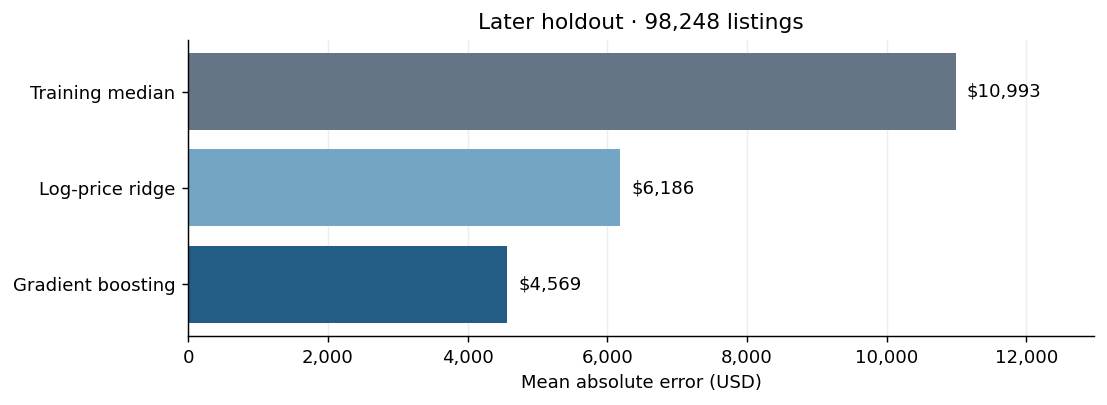

In [3]:
scores = prediction_scores(train, test)
metrics = pd.DataFrame(scores).set_index("model")
display(metrics.rename(columns={"mae": "MAE (USD)", "rmse": "RMSE (USD)", "r2": "R²"}).round(3))
winner = metrics["mae"].idxmin()
mae_gain = 100 * (1 - metrics.loc[winner, "mae"] / metrics.loc["Training median", "mae"])

fig, ax = plt.subplots(figsize=(8.4, 3.0), layout="constrained")
bars = ax.barh(metrics.index, metrics["mae"], color=[grey, pale_blue, blue])
ax.invert_yaxis()
ax.bar_label(bars, labels=[f"${value:,.0f}" for value in metrics["mae"]], padding=6)
ax.set(xlim=(0, 1.18 * metrics["mae"].max()),
       xlabel="Mean absolute error (USD)", title=f"Later holdout · {len(test):,} listings")
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="x")
plt.show()


### Adjusted associations with age and mileage

OLS uses a fixed random sample of up to 80,000 training listings with available age, usable mileage and state. It controls for the same categorical attributes as the predictive models. Non-state category levels with fewer than 40 sample observations are pooled, while missing values form an explicit level when sufficiently frequent. Log-price coefficients and their 95% state-clustered intervals are transformed as 100 × (exp(coefficient) − 1).

,Fitted difference (%),95% CI lower (%),95% CI upper (%)
contrast,,,
+5 years of age,-10.59,-11.71,-9.46
"+10,000 miles",-4.33,-4.90,-3.76


Adjusted regression: 80,000 listings; 51 state or DC clusters.


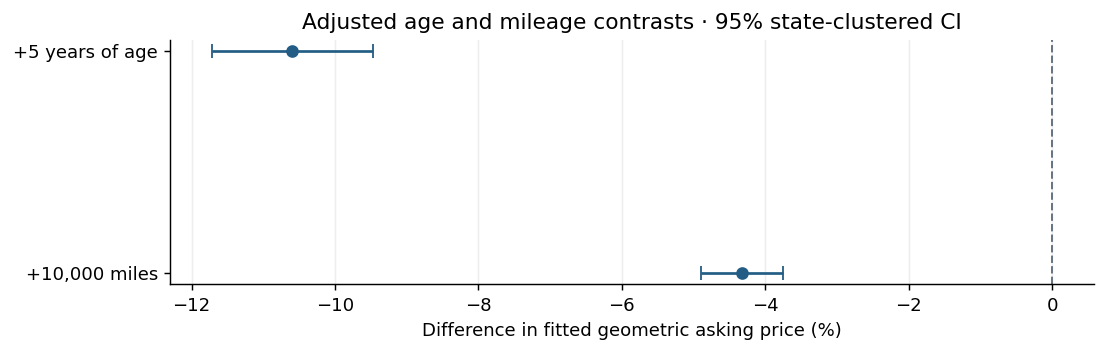

In [4]:
adjusted, adjusted_n, clusters = adjusted_associations(train)
effects = pd.DataFrame(adjusted).set_index("contrast")
display(effects.rename(columns={
    "estimate_pct": "Fitted difference (%)",
    "low_pct": "95% CI lower (%)", "high_pct": "95% CI upper (%)",
}).round(2))
print(f"Adjusted regression: {adjusted_n:,} listings; {clusters} state or DC clusters.")

fig, ax = plt.subplots(figsize=(8.4, 2.6), layout="constrained")
y = np.arange(len(effects))
estimate = effects["estimate_pct"].to_numpy()
xerr = np.vstack([estimate - effects["low_pct"], effects["high_pct"] - estimate])
ax.errorbar(estimate, y, xerr=xerr, fmt="o", color=blue, capsize=4)
ax.axvline(0, color=grey, linestyle="--", linewidth=1.1)
ax.set_yticks(y, effects.index)
ax.invert_yaxis()
ax.set(xlabel="Difference in fitted geometric asking price (%)",
       title="Adjusted age and mileage contrasts · 95% state-clustered CI")
ax.grid(axis="x")
plt.show()


## Takeaways

Read the fit and prediction results on their own scales. The associations summarize the selected earlier sample under an additive log-price model. The holdout reports predictive error for later listings in the same Kaggle snapshot. Craigslist selection, seller-entered attributes, repeated advertisements and omitted details such as trim can affect both results.

In [5]:
display(Markdown(
    f"**{winner}** had the lowest holdout MAE "
    f"(**${metrics.loc[winner, 'mae']:,.0f}**), "
    f"**{mae_gain:.1f}% lower** than the training-median baseline. "
    f"At fixed included covariates, +5 years of age corresponded to "
    f"**{effects.iloc[0]['estimate_pct']:+.1f}%** in fitted geometric asking price and "
    f"+10,000 miles to **{effects.iloc[1]['estimate_pct']:+.1f}%**."
))

summary = {
    "cohort": counts, "scores": scores, "adjusted": adjusted,
    "adjusted_n": adjusted_n, "adjusted_clusters": clusters,
    "mae_gain_pct": mae_gain, "covariates": FEATURES,
}
output = root / "outputs" / "model_summary.json"
output.parent.mkdir(exist_ok=True)
output.write_text(json.dumps(summary, indent=2), encoding="utf-8")
print(f"Saved aggregate results to {output.relative_to(root).as_posix()}.")


**Gradient boosting** had the lowest holdout MAE (**$4,569**), **58.4% lower** than the training-median baseline. At fixed included covariates, +5 years of age corresponded to **-10.6%** in fitted geometric asking price and +10,000 miles to **-4.3%**.

Saved aggregate results to outputs/model_summary.json.
